<a href="https://colab.research.google.com/github/guri19006/project-2026/blob/main/smart_collections_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#  Smart Collections: Predicting Late Invoice Payments & Cash Flow
### A company-based ML project

**The company:** *NorthBridge Supplies*, a B2B wholesaler that sends ~12,000 invoices over two years to 300 business customers.

**The problem:** Customers who pay late hurt cash flow. The collections team is small and can only chase a fraction of invoices each week. Today they chase the *biggest* invoices, which is not always the smartest choice.

**it answers 3 business questions:**
1. Which invoices are likely to be paid **late**? (classification)
2. **How many days late** will they be, and what will weekly cash inflow look like? (regression, cash-flow forecast)
3. If the team can only chase **10% of invoices**, which ones should they pick to recover the most money? (prioritization)


## 1. Setup

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import warnings; warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
rng = np.random.default_rng(42)

## 2. Build the company's data
We simulate customers (industry, size, credit score) and invoices (amount, payment terms, disputes...). Hidden "rules" make some customers naturally slower payers, and the model must discover these patterns from data, just like with real company records.

In [2]:
# ---- Customers ----
n_cust = 300
customers = pd.DataFrame({
    'customer_id': np.arange(n_cust),
    'industry': rng.choice(['Retail','Manufacturing','Healthcare','Tech','Construction','Education'], n_cust, p=[.2,.2,.15,.2,.15,.1]),
    'company_size': rng.choice(['Small','Medium','Large'], n_cust, p=[.5,.35,.15]),
    'credit_score': rng.normal(650, 70, n_cust).clip(400, 850).round(),
    'customer_since_years': rng.exponential(3, n_cust).clip(0.1, 15).round(1),
})
industry_eff = {'Construction':4,'Retail':2,'Manufacturing':1,'Healthcare':0,'Tech':-1,'Education':1.5}
size_eff = {'Small':3,'Medium':0,'Large':-2}
customers['tendency'] = ((650 - customers.credit_score) / 100 * 3
                         + customers.industry.map(industry_eff)
                         + customers.company_size.map(size_eff)
                         + rng.normal(0, 2, n_cust))

# ---- Invoices ----
n_inv = 12000
start = pd.Timestamp('2023-01-01')
w = rng.dirichlet(np.ones(n_cust) * 2)
inv = pd.DataFrame({
    'customer_id': rng.choice(n_cust, n_inv, p=w),
    'invoice_date': start + pd.to_timedelta(rng.integers(0, 730, n_inv), unit='D'),
    'amount': rng.lognormal(8.3, 0.9, n_inv).round(2),
    'terms_days': rng.choice([15, 30, 45, 60], n_inv, p=[.1, .5, .2, .2]),
    'product_category': rng.choice(['Office','Industrial','Electronics','Furniture','Packaging'], n_inv),
    'has_dispute': (rng.random(n_inv) < 0.07).astype(int),
    'early_pay_discount': (rng.random(n_inv) < 0.30).astype(int),
})
df = inv.merge(customers, on='customer_id')
df['due_date'] = df.invoice_date + pd.to_timedelta(df.terms_days, unit='D')
df['is_month_end'] = (df.invoice_date.dt.day >= 25).astype(int)

# ---- Ground truth: how late was the payment? (negative = paid early) ----
noise = rng.standard_t(4, len(df)) * 4
df['days_late'] = (df.tendency + 1.8 * np.log(df.amount / 4000) + 10 * df.has_dispute
                   - 3 * df.early_pay_discount + 2 * df.is_month_end + noise).round()
df['days_late'] = np.maximum(df.days_late, -(df.terms_days - 1))
df['paid_date'] = df.due_date + pd.to_timedelta(df.days_late, unit='D')
df['late'] = (df.days_late > 5).astype(int)

df = df.drop(columns='tendency').sort_values('invoice_date').reset_index(drop=True)
print(df.shape, f"| late rate: {df.late.mean():.1%}")
df.head()

(12000, 16) | late rate: 32.5%


,customer_id,invoice_date,amount,terms_days,product_category,has_dispute,early_pay_discount,industry,company_size,credit_score,customer_since_years,due_date,is_month_end,days_late,paid_date,late
0,272,2023-01-01,1998.36,30,Electronics,0,0,Retail,Small,718.0,5.4,2023-01-31,0,0.0,2023-01-31,0
1,256,2023-01-01,5264.12,30,Furniture,0,0,Construction,Small,623.0,0.1,2023-01-31,0,19.0,2023-02-19,1
2,136,2023-01-01,10002.99,60,Industrial,1,1,Education,Small,649.0,4.8,2023-03-02,0,9.0,2023-03-11,1
3,256,2023-01-01,3530.33,60,Industrial,0,1,Construction,Small,623.0,0.1,2023-03-02,0,-7.0,2023-02-23,0
4,45,2023-01-01,8235.52,15,Packaging,0,1,Construction,Medium,669.0,0.7,2023-01-16,0,5.0,2023-01-21,0


## 3. Explore the data

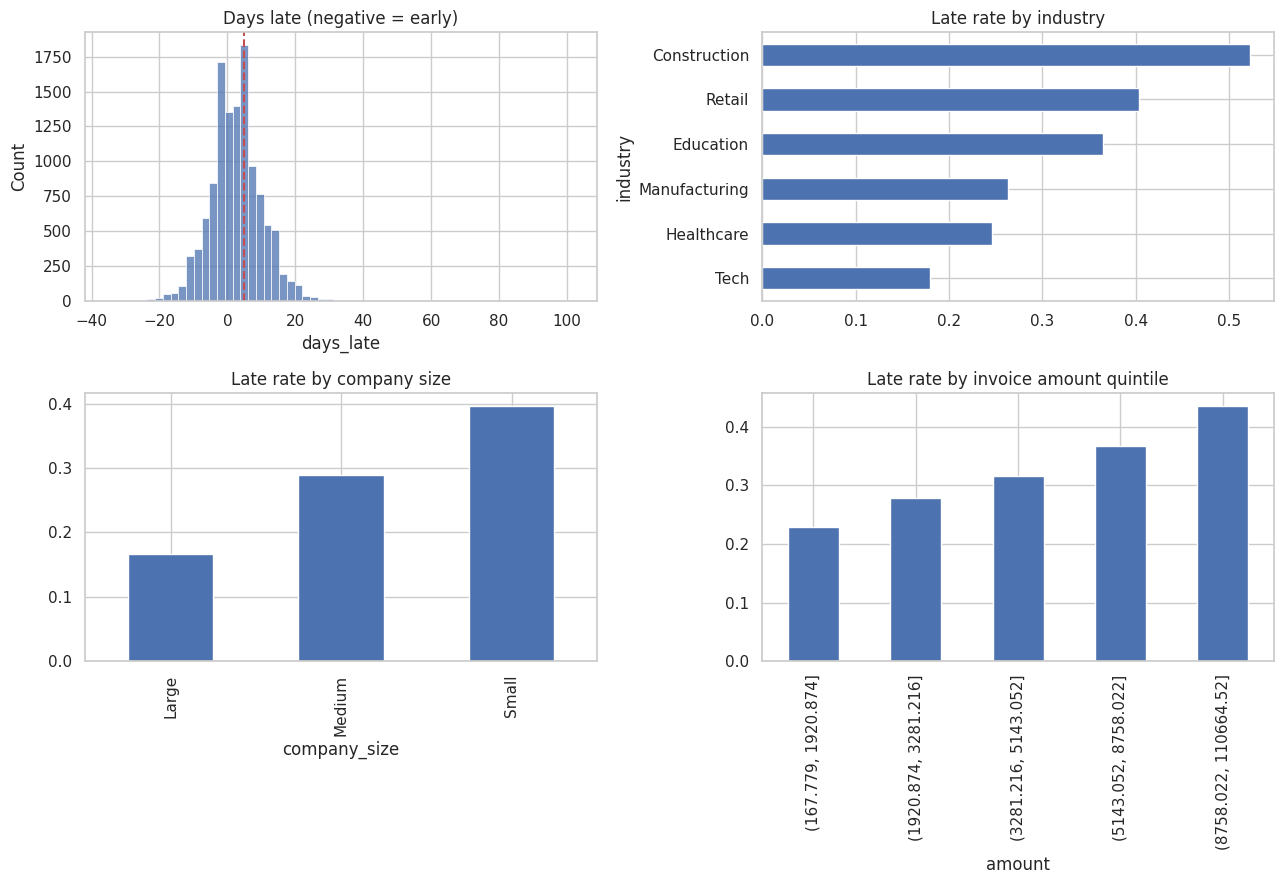

In [3]:
fig, ax = plt.subplots(2, 2, figsize=(13, 9))
sns.histplot(df.days_late, bins=60, ax=ax[0,0]); ax[0,0].set_title('Days late (negative = early)'); ax[0,0].axvline(5, color='r', ls='--')
df.groupby('industry').late.mean().sort_values().plot(kind='barh', ax=ax[0,1]); ax[0,1].set_title('Late rate by industry')
df.groupby('company_size').late.mean().plot(kind='bar', ax=ax[1,0]); ax[1,0].set_title('Late rate by company size')
df.groupby(pd.qcut(df.amount, 5)).late.mean().plot(kind='bar', ax=ax[1,1]); ax[1,1].set_title('Late rate by invoice amount quintile')
plt.tight_layout(); plt.show()

## 4. Feature engineering without data leakage
The most powerful signal is a customer's **payment history**. But at the moment an invoice is issued, you only know about invoices that were **already paid** by then. Using future information would make the model look great in the notebook and fail in real life.

For each invoice we compute history using only invoices **paid before its issue date**, plus how many invoices the customer currently has **open**.

In [4]:
out = np.full((len(df), 6), np.nan)

for cid, g in df.groupby('customer_id'):
    idx = g.index.values
    inv_d, paid_d = g['invoice_date'].values, g['paid_date'].values
    dl, lt, am = g['days_late'].values, g['late'].values, g['amount'].values
    for i in range(len(idx)):
        done = paid_d < inv_d[i]
        opn  = (inv_d < inv_d[i]) & (paid_d >= inv_d[i])
        out[idx[i], 0] = done.sum()
        if done.any():
            out[idx[i], 1] = dl[done].mean()
            out[idx[i], 2] = lt[done].mean()
            out[idx[i], 3] = dl[done].max()
        out[idx[i], 4] = opn.sum()
        out[idx[i], 5] = am[opn].sum()

df[['hist_n','hist_avg_late','hist_late_rate','hist_max_late','open_count','open_amount']] = out
df['inv_dow'] = df.invoice_date.dt.dayofweek
df['inv_month'] = df.invoice_date.dt.month
df[['customer_id','invoice_date','hist_n','hist_avg_late','hist_late_rate','open_count']].tail()

,customer_id,invoice_date,hist_n,hist_avg_late,hist_late_rate,open_count
11995,143,2024-12-30,75.0,3.120000,0.240000,5.0
11996,106,2024-12-30,43.0,2.720930,0.209302,2.0
11997,218,2024-12-30,15.0,7.266667,0.400000,2.0
11998,137,2024-12-30,161.0,-0.093168,0.167702,5.0
11999,291,2024-12-30,66.0,6.439394,0.500000,1.0


## 5. Time-based split
Random splits would let the model peek at the future. Instead we **train on the past and test on the future**, exactly how it would be used in production. We also only train on invoices whose outcome was already known at the cutoff date.

In [5]:
cutoff = start + pd.Timedelta(days=540)

train = df[(df.invoice_date < cutoff) & (df.paid_date <= cutoff)]
test  = df[df.invoice_date >= cutoff]
print(f"Train: {len(train)} invoices | Test: {len(test)} invoices | cutoff = {cutoff.date()}")

num_cols = ['amount','terms_days','credit_score','customer_since_years','hist_n','hist_avg_late','hist_late_rate',
            'hist_max_late','open_count','open_amount','is_month_end','inv_dow','inv_month','has_dispute','early_pay_discount']
cat_cols = ['industry','company_size','product_category']
features = cat_cols + num_cols

X_train, X_test = train[features], test[features]
y_train, y_test = train.late, test.late
print(f"Late rate  train: {y_train.mean():.1%} | test: {y_test.mean():.1%}")

Train: 8178 invoices | Test: 3166 invoices | cutoff = 2024-06-24
Late rate  train: 32.0% | test: 32.5%


## 6. Models: baseline vs. logistic regression vs. gradient boosting

In [6]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, average_precision_score

# Baseline: 'a customer who was often late will be late again'
baseline = X_test.hist_late_rate.fillna(y_train.mean())

# Logistic regression
logit = Pipeline([
    ('prep', ColumnTransformer([
        ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())]), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)])),
    ('clf', LogisticRegression(max_iter=2000))])

# Gradient boosting (handles missing values + categories natively)
def make_gbm(**kw):
    prep = ColumnTransformer([('cat', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1), cat_cols)],
                             remainder='passthrough')
    mask = [True] * len(cat_cols) + [False] * len(num_cols)
    return Pipeline([('prep', prep),
                     ('clf', HistGradientBoostingClassifier(categorical_features=mask, random_state=42, **kw))])

gbm = make_gbm(learning_rate=0.05, max_iter=300, max_depth=4, l2_regularization=1.0)

logit.fit(X_train, y_train); gbm.fit(X_train, y_train)
p_logit, p_gbm = logit.predict_proba(X_test)[:, 1], gbm.predict_proba(X_test)[:, 1]

res = pd.DataFrame({
    'ROC-AUC': {'Baseline (history)': roc_auc_score(y_test, baseline), 'Logistic Regression': roc_auc_score(y_test, p_logit), 'Gradient Boosting': roc_auc_score(y_test, p_gbm)},
    'PR-AUC':  {'Baseline (history)': average_precision_score(y_test, baseline), 'Logistic Regression': average_precision_score(y_test, p_logit), 'Gradient Boosting': average_precision_score(y_test, p_gbm)},
}).round(3)
res

,ROC-AUC,PR-AUC
Baseline (history),0.747,0.571
Logistic Regression,0.837,0.736
Gradient Boosting,0.832,0.728


## 7. Can we trust the probabilities? (calibration)
Collections managers will use these numbers to make decisions, so *a '70% risk' should really mean about 70% of such invoices are late*.

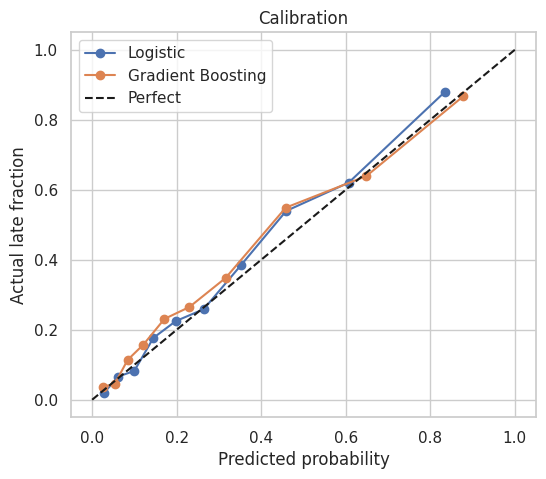

In [7]:
from sklearn.calibration import calibration_curve

plt.figure(figsize=(6, 5))
for name, p in [('Logistic', p_logit), ('Gradient Boosting', p_gbm)]:
    frac, mean_p = calibration_curve(y_test, p, n_bins=10, strategy='quantile')
    plt.plot(mean_p, frac, marker='o', label=name)
plt.plot([0, 1], [0, 1], 'k--', label='Perfect')
plt.xlabel('Predicted probability'); plt.ylabel('Actual late fraction'); plt.legend(); plt.title('Calibration'); plt.show()

## 8.  The business payoff: whom should the collectors call?
The team can chase only **10% of invoices**. We compare four strategies by how many *dollars of truly-late invoices* each one reaches.

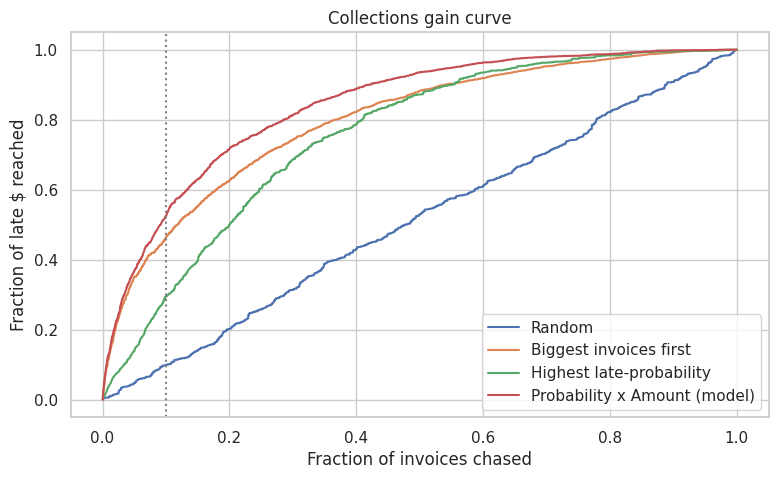

Late dollars reached when chasing the top 10% of invoices:
Random                           9.9%
Biggest invoices first          46.3%
Highest late-probability        29.5%
Probability x Amount (model)    52.6%


In [8]:
amount = test.amount.values
late_dollars = amount * y_test.values
total_late = late_dollars.sum()
n = len(test)

strategies = {
    'Random':                       rng.random(n),
    'Biggest invoices first':       amount,
    'Highest late-probability':     p_gbm,
    'Probability x Amount (model)': p_gbm * amount,
}

plt.figure(figsize=(9, 5))
summary = {}
for name, score in strategies.items():
    order = np.argsort(-score)
    gain = np.cumsum(late_dollars[order]) / total_late
    x = np.arange(1, n + 1) / n
    plt.plot(x, gain, label=name)
    summary[name] = gain[int(0.10 * n) - 1]
plt.axvline(0.10, color='gray', ls=':')
plt.xlabel('Fraction of invoices chased'); plt.ylabel('Fraction of late $ reached'); plt.legend(); plt.title('Collections gain curve'); plt.show()

print("Late dollars reached when chasing the top 10% of invoices:")
print(pd.Series(summary).map('{:.1%}'.format).to_string())

## 9. Predicting *how late*: a cash-flow forecast
Finance wants to know *when* money will actually arrive. We train a regression model on `days_late` and forecast weekly cash inflow.

MAE of days-late prediction: model 4.36 days  vs  'always on time' guess 6.18 days


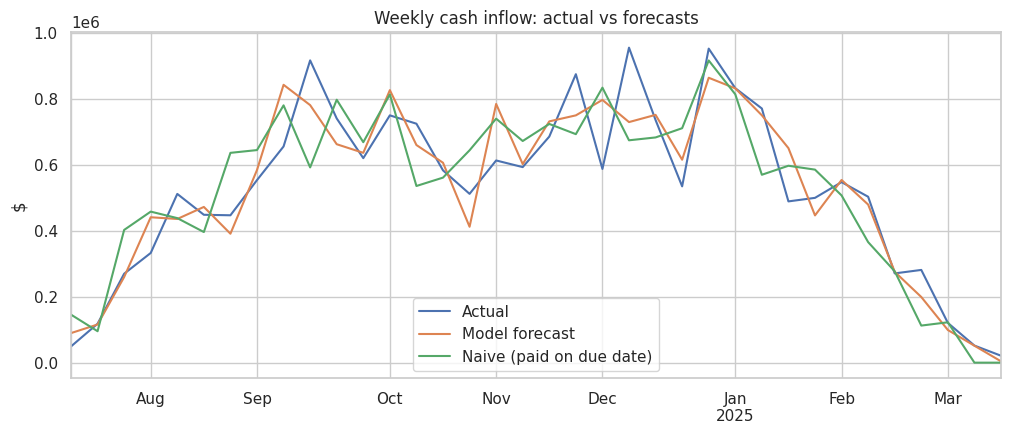

Weekly MAE ($):
Model forecast               66374.0
Naive (paid on due date)    105562.0


In [9]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error

reg_prep = ColumnTransformer([('cat', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1), cat_cols)], remainder='passthrough')
mask = [True] * len(cat_cols) + [False] * len(num_cols)
reg = Pipeline([('prep', reg_prep),
                ('reg', HistGradientBoostingRegressor(categorical_features=mask, learning_rate=0.05, max_iter=300, max_depth=4, random_state=42))])
reg.fit(X_train, train.days_late)

pred_days = reg.predict(X_test)
print(f"MAE of days-late prediction: model {mean_absolute_error(test.days_late, pred_days):.2f} days"
      f"  vs  'always on time' guess {mean_absolute_error(test.days_late, np.zeros(n)):.2f} days")

fc = test[['due_date','paid_date','amount']].copy()
fc['pred_paid'] = fc.due_date + pd.to_timedelta(np.round(pred_days), unit='D')

weekly = lambda col: fc.groupby(pd.Grouper(key=col, freq='W'))['amount'].sum()
actual, model_fc, naive = weekly('paid_date'), weekly('pred_paid'), weekly('due_date')
cmp = pd.concat([actual, model_fc, naive], axis=1, keys=['Actual', 'Model forecast', 'Naive (paid on due date)']).fillna(0)
cmp = cmp.iloc[2:-2]
cmp.plot(figsize=(12, 4.5)); plt.title('Weekly cash inflow: actual vs forecasts'); plt.ylabel('$'); plt.show()
print("Weekly MAE ($):")
print((cmp[['Model forecast','Naive (paid on due date)']].sub(cmp['Actual'], axis=0).abs().mean()).round(0).to_string())

## 10. What drives late payments? (explainability)

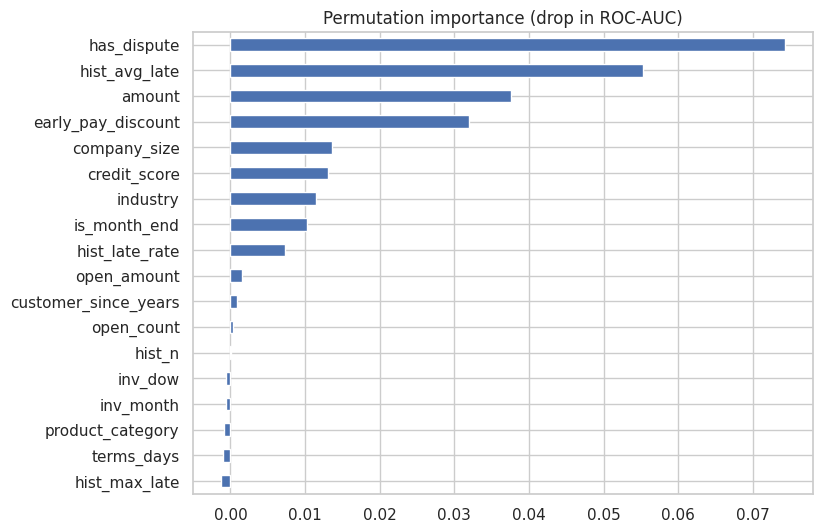

In [10]:
from sklearn.inspection import permutation_importance

r = permutation_importance(gbm, X_test, y_test, scoring='roc_auc', n_repeats=5, random_state=42, n_jobs=-1)
imp = pd.Series(r.importances_mean, index=features).sort_values()
imp.plot(kind='barh', figsize=(8, 6)); plt.title('Permutation importance (drop in ROC-AUC)'); plt.show()

## 11. Weekly action list for the collections team

In [11]:
def risk_tier(p):
    return 'HIGH: call now' if p >= 0.6 else ('MEDIUM: send reminder' if p >= 0.35 else 'LOW: no action')

action = test[['customer_id','industry','amount','terms_days','due_date']].copy()
action['late_prob'] = p_gbm
action['expected_days_late'] = pred_days.round(1)
action['expected_late_$'] = (p_gbm * amount).round(0)
action['action'] = action.late_prob.map(risk_tier)
action.sort_values('expected_late_$', ascending=False).head(15)

,customer_id,industry,amount,terms_days,due_date,late_prob,expected_days_late,expected_late_$,action
10883,251,Construction,80396.43,30,2024-11-25,0.568321,7.3,45691.0,MEDIUM: send reminder
8909,161,Education,53204.17,30,2024-07-28,0.827583,9.3,44031.0,HIGH: call now
10273,38,Manufacturing,48286.66,45,2024-11-03,0.864655,8.8,41751.0,HIGH: call now
10786,295,Education,81940.04,30,2024-11-19,0.505359,7.7,41409.0,MEDIUM: send reminder
9990,70,Manufacturing,62682.11,30,2024-10-02,0.646357,8.1,40515.0,HIGH: call now
9071,235,Construction,43912.83,45,2024-08-22,0.825275,13.7,36240.0,HIGH: call now
10044,273,Tech,34279.29,60,2024-11-04,0.982514,13.5,33680.0,HIGH: call now
11733,38,Manufacturing,71832.57,45,2025-01-29,0.464898,5.3,33395.0,MEDIUM: send reminder
11187,267,Retail,38885.52,45,2024-12-29,0.846852,10.7,32930.0,HIGH: call now
9318,54,Tech,35386.22,30,2024-08-23,0.848298,10.4,30018.0,HIGH: call now


In [12]:
# Score a brand-new invoice (this is how it'd work in production)
def score_invoice(**inv):
    row = pd.DataFrame([inv])[features]
    p = gbm.predict_proba(row)[0, 1]
    d = reg.predict(row)[0]
    return f"Late probability: {p:.0%} | expected {d:+.1f} days vs due date | {risk_tier(p)}"

sample = X_test.iloc[0].to_dict()
print(score_invoice(**sample))
sample.update(has_dispute=1, hist_avg_late=15, hist_late_rate=0.8, hist_max_late=30)
print(score_invoice(**sample))

Late probability: 21% | expected +2.4 days vs due date | LOW: no action
Late probability: 89% | expected +16.3 days vs due date | HIGH: call now


## 12. Save the models

In [13]:
import joblib
joblib.dump({'classifier': gbm, 'regressor': reg, 'features': features}, 'collections_models.joblib')
from google.colab import files; files.download('collections_models.joblib')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>